In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("C:\Customer_Churn_Analysis\Data\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [2]:
# Calculate churn rate by contract and internet service
contract_internet_churn = pd.crosstab(
    [df["Contract"], df["InternetService"]],
    df["Churn"],
    normalize="index"
) * 100

print(contract_internet_churn)

Churn                                  No        Yes
Contract       InternetService                      
Month-to-month DSL              67.784137  32.215863
               Fiber optic      45.394737  54.605263
               No               81.106870  18.893130
One year       DSL              90.701754   9.298246
               Fiber optic      80.705009  19.294991
               No               97.527473   2.472527
Two year       DSL              98.089172   1.910828
               Fiber optic      92.773893   7.226107
               No               99.216301   0.783699


In [3]:
# Calculate churn rate by contract and payment method
contract_payment_churn = pd.crosstab(
    [df["Contract"], df["PaymentMethod"]],
    df["Churn"],
    normalize="index"
) * 100

print(contract_payment_churn)

Churn                                            No        Yes
Contract       PaymentMethod                                  
Month-to-month Bank transfer (automatic)  65.874363  34.125637
               Credit card (automatic)    67.219153  32.780847
               Electronic check           46.270270  53.729730
               Mailed check               68.421053  31.578947
One year       Bank transfer (automatic)  90.281330   9.718670
               Credit card (automatic)    89.698492  10.301508
               Electronic check           81.556196  18.443804
               Mailed check               93.175074   6.824926
Two year       Bank transfer (automatic)  96.631206   3.368794
               Credit card (automatic)    97.762478   2.237522
               Electronic check           92.261905   7.738095
               Mailed check               99.214660   0.785340


In [4]:
# Calculate churn rate by internet service and technical support
internet_techsupport_churn = pd.crosstab(
    [df["InternetService"], df["TechSupport"]],
    df["Churn"],
    normalize="index"
) * 100

print(internet_techsupport_churn)

Churn                                       No        Yes
InternetService TechSupport                              
DSL             No                   72.244570  27.755430
                Yes                  90.322581   9.677419
Fiber optic     No                   50.627803  49.372197
                Yes                  77.367206  22.632794
No              No internet service  92.595020   7.404980


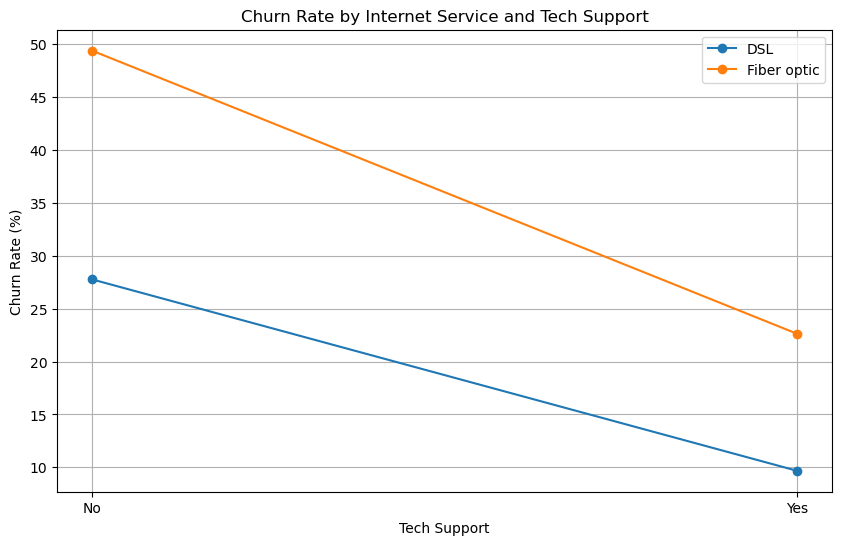

In [6]:

# Prepare churn rates for visualization
plot_data = internet_techsupport_churn["Yes"].reset_index()

# Create the chart
plt.figure(figsize=(10, 6))

for internet_type in plot_data["InternetService"].unique():
    subset = plot_data[plot_data["InternetService"] == internet_type]
    
    if internet_type != "No":
        plt.plot(
            subset["TechSupport"],
            subset["Yes"],
            marker="o",
            label=internet_type
        )

plt.title("Churn Rate by Internet Service and Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
# Create a summary of selected high-risk customer groups
high_risk_groups = {
    "Month-to-month + Fiber optic": 54.61,
    "Month-to-month + Electronic check": 53.73,
    "Fiber optic + No TechSupport": 49.37,
    "Electronic check": 45.29,
    "Month-to-month": 42.71,
    "Fiber optic": 41.89
}

# Convert the dictionary to a DataFrame
high_risk_df = pd.DataFrame(
    list(high_risk_groups.items()),
    columns=["Customer Group", "Churn Rate (%)"]
)

# Sort from highest to lowest churn rate
high_risk_df = high_risk_df.sort_values(
    by="Churn Rate (%)",
    ascending=False
)

print(high_risk_df)

                      Customer Group  Churn Rate (%)
0       Month-to-month + Fiber optic           54.61
1  Month-to-month + Electronic check           53.73
2       Fiber optic + No TechSupport           49.37
3                   Electronic check           45.29
4                     Month-to-month           42.71
5                        Fiber optic           41.89


## Day 5 Findings

### Contract and Internet Service
- Month-to-month customers with Fiber optic internet had the highest churn rate at 54.61%.
- Month-to-month customers with DSL had a churn rate of 32.22%.
- Longer-term contracts showed substantially lower churn rates across internet service types.
- Contract type and internet service together provide stronger insights than analyzing each variable separately.

### Contract and Payment Method
- Month-to-month customers using Electronic check had a churn rate of 53.73%.
- This was the highest churn rate among the contract and payment method combinations analyzed.
- Longer-term contracts generally showed lower churn rates across payment methods.

### Internet Service and Tech Support
- Fiber optic customers without Tech Support had a churn rate of 49.37%.
- Fiber optic customers with Tech Support had a lower churn rate of 22.63%.
- DSL customers without Tech Support had a churn rate of 27.76%.
- DSL customers with Tech Support had a churn rate of 9.68%.
- Tech Support showed a lower churn rate within both DSL and Fiber optic groups.

### High-Risk Customer Groups
- Month-to-month + Fiber optic: 54.61%
- Month-to-month + Electronic check: 53.73%
- Fiber optic + No TechSupport: 49.37%
- Electronic check: 45.29%
- Month-to-month: 42.71%
- Fiber optic: 41.89%

### Overall Day 5 Insight
- Combining multiple customer characteristics reveals stronger patterns than analyzing individual variables alone.
- Month-to-month contracts, Fiber optic internet, Electronic check payment, and lack of Tech Support appear repeatedly among higher-churn groups.
- These results represent associations in the dataset and do not prove that any individual factor causes customer churn.